# Pull Request Title and Body Analysis

This notebook analyzes ~23,000 pull requests and focuses only on the titles and body of the data.

#### Import Dependencies

This section loads the Python libraries used for data processing, visualization, and file management. The display and plotting settings are configured to make tabular summaries and figures easier to review.

In [20]:
import os
import sys
from dotenv import load_dotenv

'''
from azure.ai.inference import ChatCompletionsClient
from azure.ai.inference.models import SystemMessage, UserMessage
from azure.core.credentials import AzureKeyCredential

load_dotenv()

print(sys.executable)

token = os.environ.get("GITHUB_TOKEN")
print("Token loaded:", token is not None)

if token is None:
    raise ValueError("GITHUB_TOKEN was not found. Check your .env file or environment variable.")

endpoint = "https://models.github.ai/inference"
model = "openai/gpt-5-nano"

client = ChatCompletionsClient(
    endpoint=endpoint,
    credential=AzureKeyCredential(token),
)

response = client.complete(
    messages=[
        SystemMessage(content="You are a helpful assistant."),
        UserMessage(content="What is the capital of US?"),
    ],
    model=model,
)

print(response.choices[0].message.content)
'''


'\nfrom azure.ai.inference import ChatCompletionsClient\nfrom azure.ai.inference.models import SystemMessage, UserMessage\nfrom azure.core.credentials import AzureKeyCredential\n\nload_dotenv()\n\nprint(sys.executable)\n\ntoken = os.environ.get("GITHUB_TOKEN")\nprint("Token loaded:", token is not None)\n\nif token is None:\n    raise ValueError("GITHUB_TOKEN was not found. Check your .env file or environment variable.")\n\nendpoint = "https://models.github.ai/inference"\nmodel = "openai/gpt-5-nano"\n\nclient = ChatCompletionsClient(\n    endpoint=endpoint,\n    credential=AzureKeyCredential(token),\n)\n\nresponse = client.complete(\n    messages=[\n        SystemMessage(content="You are a helpful assistant."),\n        UserMessage(content="What is the capital of US?"),\n    ],\n    model=model,\n)\n\nprint(response.choices[0].message.content)\n'

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 100)

sns.set_theme(style='whitegrid', context='notebook', palette='husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

#### Load Dataset

This section loads the public and private pull requests. We look at data from PRs collected from **October 2025 → June 2026**. All files are combined into a single analysis dataset with a repository-type label so that we can compare repositories directly. We also make sure PRs are unique.

In [27]:
data_dir = Path("../data")

pr_files = [
    "combined_pr_data.csv",
]

pr_dfs = []

for file in pr_files:
    df = pd.read_csv(data_dir / file)
    df["source_file"] = file
    df["repo_type"] = "private" if "private" in file.lower() else "public"
    pr_dfs.append(df)

combined_df = pd.concat(pr_dfs, ignore_index=True)

print(f"Combined dataframe shape: {combined_df.shape}")
print(combined_df.columns)
combined_df.head()

Combined dataframe shape: (25034, 24)
Index(['pull_request_id', 'repository_id', 'author_id', 'is_public',
       'repo_group', 'repo_primary_language', 'created_at', 'merged_at',
       'closed_at', 'final_state', 'title', 'body', 'lines_added',
       'lines_deleted', 'files_added', 'files_deleted', 'files_modified',
       'diff_hunks', 'num_commits', 'num_review_comments', 'num_reviewers',
       'minutes_to_merge', 'source_file', 'repo_type'],
      dtype='str')


,pull_request_id,repository_id,author_id,is_public,repo_group,repo_primary_language,created_at,merged_at,closed_at,final_state,title,body,lines_added,lines_deleted,files_added,files_deleted,files_modified,diff_hunks,num_commits,num_review_comments,num_reviewers,minutes_to_merge,source_file,repo_type
0,3103976472,1105553986,120586566,False,industrial,Java,2025-12-15 20:53:45.000+00:00,2025-12-15 21:04:00.000+00:00,2025-12-15 21:04:00.000+00:00,merged,PR criado automaticamente. release/v0.0.8 <- develop,NaN,32300,497,456,14,15,0,NaN,0,0,10,combined_pr_data.csv,public
1,3169426375,1013193728,49699333,False,industrial,Kotlin,2026-01-13 11:54:42.000+00:00,2026-01-20 06:37:52.000+00:00,2026-01-20 06:37:52.000+00:00,merged,Bump the tolletaten-workflows group with 4 updates,Bumps the tolletaten-workflows group with 4 updates: [tolletaten/actions/.github/workflows/maven...,9,9,0,0,9,0,NaN,1,2,9763,combined_pr_data.csv,public
2,3122661687,1098056443,92954774,False,industrial,JavaScript,2025-12-22 11:43:59.000+00:00,2025-12-23 07:21:26.000+00:00,2025-12-23 07:21:26.000+00:00,merged,Forecast filter changes,NaN,1777,1554,0,0,6,0,NaN,0,1,1177,combined_pr_data.csv,public
3,3123398093,1009660877,218757633,False,industrial,HCL,2025-12-22 15:57:10.000+00:00,2025-12-22 16:02:27.000+00:00,2025-12-22 16:02:27.000+00:00,merged,Updated VCSprovider and repo url with GitHub references in jib.yml and Jenkins file,Updated VCSprovider and repo url with GitHub references in jib.yml and Jenkins file,31,27,0,0,2,0,NaN,1,10,5,combined_pr_data.csv,public
4,3137889785,931020597,157427842,False,industrial,Go,2025-12-30 21:56:52.000+00:00,2026-01-02 22:48:59.000+00:00,2026-01-02 22:48:59.000+00:00,merged,Turn off force clearing of SOCKHASH maps by default,Since unread redirected bytes are held in ingress queues tied to the lifetime of the SOCKHASH ma...,17,50,0,0,2,0,NaN,0,4,4372,combined_pr_data.csv,public


#### Checking for Missing Values & Duplicates Analysis
This section compares missing values across the dataset and checks that each PR is unique. In this workflow, I pull data from multiple SQL queries. Since I am using multiple CSV files, there is a chance that the same PR may be pulled in more than once. To prevent this, I check for duplicate PRs across all CSV files.

In [28]:
# Check missing values and duplicate data from combined_df only

df = combined_df.copy()

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_%": (df.isna().mean().values * 100).round(2),
    "Non_Missing_Count": df.notna().sum().values,
    "Total_Rows": len(df)
})

missing_summary = missing_summary.sort_values("Missing_%", ascending=False)

# Show only columns that actually have missing values
# missing_only = missing_summary[missing_summary["Missing_Count"] > 0]
# print("\n=== COLUMNS WITH MISSING VALUES ONLY ===")
# display(missing_only)

# -----------------------------
# Make sure each PR is unique
# -----------------------------
pr_key = ["repository_id", "pull_request_id"]

# Check that both columns exist
missing_key_cols = [col for col in pr_key if col not in df.columns]

if missing_key_cols:
    raise ValueError(f"Missing key columns: {missing_key_cols}")

print("=== BEFORE DEDUPLICATION ===")
print(f"Rows: {len(df):,}")
print(f"Unique repository_id + pull_request_id pairs: {df[pr_key].drop_duplicates().shape[0]:,}")

duplicate_pr_count = df.duplicated(subset=pr_key).sum()
print(f"Duplicate PR rows: {duplicate_pr_count:,}")


# -----------------------------
# Deduplicate
# -----------------------------
# Keep the first version of each repository_id + pull_request_id pair.
# This keeps one row per PR.

combined_df_unique = (
    df
    .drop_duplicates(subset=pr_key, keep="first")
    .reset_index(drop=True)
)

=== BEFORE DEDUPLICATION ===
Rows: 25,034
Unique repository_id + pull_request_id pairs: 21,643
Duplicate PR rows: 3,391


In [24]:
PLOT_OUTPUT_DIR = Path('dataset_plots')
PLOT_OUTPUT_DIR.mkdir(exist_ok=True)

def save_plot(fig, filename):
    path = PLOT_OUTPUT_DIR / filename
    plt.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'Saved: {path}')
    plt.show()
    plt.close(fig)
    return path

## Clean title and body text
In this section we walk through how we can process the data from the titles and body of the data in order to gain some insights. We hope to draw conclusion about the relationships between the lines of code added in the pull request, the time to time merge and the contents of the title/body of the pull requests. 

In [46]:
import re
from langdetect import DetectorFactory, LangDetectException, detect

DetectorFactory.seed = 42

TITLE_COL = "title"
BODY_COL = "body"

missing_text_cols = [col for col in [TITLE_COL, BODY_COL] if col not in combined_df.columns]
if missing_text_cols:
    raise ValueError(f"Missing text columns: {missing_text_cols}")

df = combined_df_unique.copy() if "combined_df_unique" in globals() else combined_df.copy()

DEFAULT_STOPWORDS = {
    "a", "an", "and", "are", "as", "at", "be", "by", "for", "from", "has", "have",
    "in", "into", "is", "it", "its", "of", "on", "or", "that", "the", "this", "to",
    "was", "were", "will", "with", "without", "we", "you", "your", "our", "their",
    "pr", "pull", "request", "merge", "merged", "branch", "commit", "commits", "github",
    "com", "http", "https", "www", "url", "urls", "href", "hrefs", "id", "ids", "file",
    "files", "code", "change", "changes", "update", "updates", "updated", "add", "added",
    "remove", "removed", "use", "using", "used", "new", "old", "make", "made", "set",
    "get", "also", "one", "two", "true", "false", "none", "null", "na", "n", "amp",
    "nbsp", "src", "lib", "app", "main", "test", "tests", "spec", "specs", "tmp", "var",
    "const", "let", "function", "class", "method", "api", "utils", "util", "service",
    "component", "module", "object", "data", "value", "values", "type", "types", "bot",
    "ref", "refs", "issue_ref", "ticket_ref",
}
EXTRA_STOPWORDS = set()
STOPWORDS = DEFAULT_STOPWORDS | EXTRA_STOPWORDS
NOISE_TOKEN_PARTS = ("bot",)

def normalize_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = re.sub(r"```.*?```", " ", text, flags=re.DOTALL)
    text = re.sub(r"`[^`]+`", " ", text)
    text = re.sub(r"&nbsp;|\bnbsp\b", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"https?://\S+", " URL ", text)
    text = re.sub(r"#[0-9]+", " ", text)
    text = re.sub(r"\b[A-Z][A-Z0-9]+-\d+\b", " ", text)
    text = text.replace("_", " ").replace("-", " ").replace("/", " ")
    text = re.sub(r"[^A-Za-z0-9#+. ]+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

def tokenize(text, min_len=3):
    raw_terms = re.findall(r"[a-z][a-z0-9+#.]*", str(text).lower())
    terms = [term.strip("#+.") for term in raw_terms]
    return [
        term
        for term in terms
        if len(term) >= min_len
        and term not in STOPWORDS
        and not term.isdigit()
        and not any(noise_part in term for noise_part in NOISE_TOKEN_PARTS)
    ]

def clean_for_nlp(text):
    return " ".join(tokenize(normalize_text(text)))

def detect_pr_language(row):
    text = f"{row[TITLE_COL]} {row[BODY_COL]}".strip()
    text = normalize_text(text)
    if len(text) < 20:
        return "unknown"
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"

def word_count(text):
    text = "" if pd.isna(text) else str(text)
    return len(re.findall(r"\b\w+\b", text))

def q90(values):
    values = pd.to_numeric(values, errors="coerce").dropna()
    return values.quantile(0.90) if len(values) else np.nan

for col in ["minutes_to_merge", "lines_added", "lines_deleted", "files_added", "files_deleted", "files_modified", "num_reviewers", "num_review_comments"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

zero_series = pd.Series(0, index=df.index)
lines_added = df["lines_added"] if "lines_added" in df.columns else zero_series
lines_deleted = df["lines_deleted"] if "lines_deleted" in df.columns else zero_series
files_added = df["files_added"] if "files_added" in df.columns else zero_series
files_deleted = df["files_deleted"] if "files_deleted" in df.columns else zero_series
files_modified = df["files_modified"] if "files_modified" in df.columns else zero_series

df["lines_modified"] = df["lines_modified"] if "lines_modified" in df.columns else lines_added.fillna(0) + lines_deleted.fillna(0)
df["files_touched"] = df["files_touched"] if "files_touched" in df.columns else files_added.fillna(0) + files_deleted.fillna(0) + files_modified.fillna(0)
df["complexity_score"] = df["complexity_score"] if "complexity_score" in df.columns else df["lines_modified"] + (10 * df["files_touched"])

if "user_id" not in df.columns:
    df["user_id"] = df["author_id"] if "author_id" in df.columns else np.arange(len(df))
for col in ["pull_request_id", "repository_id", "num_reviewers", "num_review_comments", "minutes_to_merge"]:
    if col not in df.columns:
        df[col] = np.nan

df[TITLE_COL] = df[TITLE_COL].fillna("").astype(str)
df[BODY_COL] = df[BODY_COL].fillna("").astype(str)
df["title_clean"] = df[TITLE_COL].str.strip()
df["body_clean"] = df[BODY_COL].str.strip()
df["title_lower"] = df["title_clean"].str.lower()
df["body_lower"] = df["body_clean"].str.lower()
df["detected_language"] = df.apply(detect_pr_language, axis=1)
language_counts_before_filter = df["detected_language"].value_counts(dropna=False)
rows_before_language_filter = len(df)
df = df[df["detected_language"].eq("en")].reset_index(drop=True)
rows_removed_non_english = rows_before_language_filter - len(df)

df["title_clean_nlp"] = df[TITLE_COL].apply(clean_for_nlp)
df["body_clean_nlp"] = df[BODY_COL].apply(clean_for_nlp)
df["combined_text_nlp"] = (df["title_clean_nlp"] + " " + df["body_clean_nlp"]).str.strip()
df["title_word_count"] = df["title_clean"].apply(word_count)
df["body_word_count"] = df["body_clean"].apply(word_count)
df["has_title"] = df["title_word_count"] > 0
df["has_body"] = df["body_word_count"] > 0
df["short_body"] = df["body_word_count"] < 20

print(f"Rows before language filter: {rows_before_language_filter:,}")
print(f"Rows after English-only filter: {len(df):,}")
print(f"Rows removed as non-English or unknown: {rows_removed_non_english:,}")
display(language_counts_before_filter.head(20).rename_axis("detected_language").reset_index(name="pr_count"))
df[[TITLE_COL, BODY_COL, "detected_language", "title_word_count", "body_word_count", "combined_text_nlp"]].head()

Rows before language filter: 21,643
Rows after English-only filter: 16,598
Rows removed as non-English or unknown: 5,045


,detected_language,pr_count
0,en,16598
1,unknown,2359
2,pt,506
3,fr,402
4,ca,283
5,it,257
6,ro,254
7,es,227
8,da,153
9,sv,98


,title,body,detected_language,title_word_count,body_word_count,combined_text_nlp
0,Bump the tolletaten-workflows group with 4 updates,Bumps the tolletaten-workflows group with 4 updates: [tolletaten/actions/.github/workflows/maven...,en,8,5496,bump tolletaten workflows group bumps tolletaten workflows group tolletaten actions workflows ma...
1,Forecast filter changes,,en,3,0,forecast filter
2,Updated VCSprovider and repo url with GitHub references in jib.yml and Jenkins file,Updated VCSprovider and repo url with GitHub references in jib.yml and Jenkins file,en,14,14,vcsprovider repo references jib.yml jenkins vcsprovider repo references jib.yml jenkins
3,Turn off force clearing of SOCKHASH maps by default,Since unread redirected bytes are held in ingress queues tied to the lifetime of the SOCKHASH ma...,en,9,203,turn off force clearing sockhash maps default since unread redirected bytes held ingress queues ...
4,[cherry-pick | m>r] fix(dashboard-stats): minor valueunit cleanup + query edits from feedback #993,SDWEB-1042\n\n---\n\nCherry-Picked from #993 (96fc9ff84e9c8f0a17c89c062c44fa1ae31e8330),en,15,7,cherry pick fix dashboard stats minor valueunit cleanup query edits feedback cherry picked fc9ff...


In [35]:
bot_noise_count = int(df["combined_text_nlp"].str.contains("bot", regex=False).sum())
print({"rows_with_bot_fragment": bot_noise_count})

df.loc[
    df["combined_text_nlp"].str.contains("bot", regex=False),
    [TITLE_COL, BODY_COL, "combined_text_nlp"],
].head(10)

{'rows_with_bot_fragment': 0}


,title,body,combined_text_nlp


## Word cloud

A word cloud is a fast visual for the most common title/body terms.


,theme_id,theme_label,top_terms,n_documents
5,6,Theme 6: issue / issue ref / ref,"issue, issue ref, ref, fix, feature, release, ref issue, fixes, documentation, breaking, descrip...",7838
1,2,Theme 2: ticket / ticket ref / ref,"ticket, ticket ref, ref, ref ticket, jira, fix, feat, feat ticket, jira ticket, ref fix, fix tic...",3333
2,3,Theme 3: details / summary / stop,"details, summary, stop, close stop, reopen, close, upgrade, stop creating, unless, version, crea...",2377
4,5,Theme 5: img width / height alt / width,"img width, height alt, width, width height, height, alt, img, alt image, image, screenshot, alt ...",1399
3,4,Theme 4: schedule / rebase / renovate,"schedule, rebase, renovate, rebase retry, retry, schedule defined, time schedule, defined autome...",1114
0,1,Theme 1: help open / source alive / alpha help,"help open, source alive, alpha help, img valign, v2 alpha, valign v2, alive sponsor, created img...",973


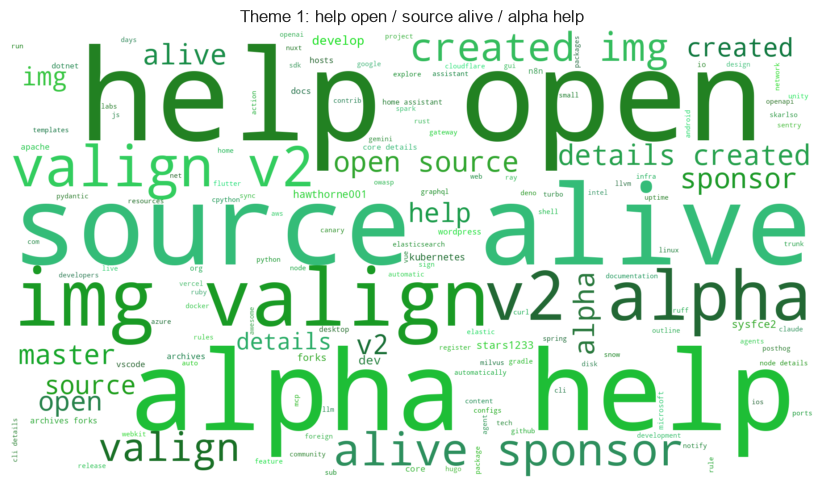

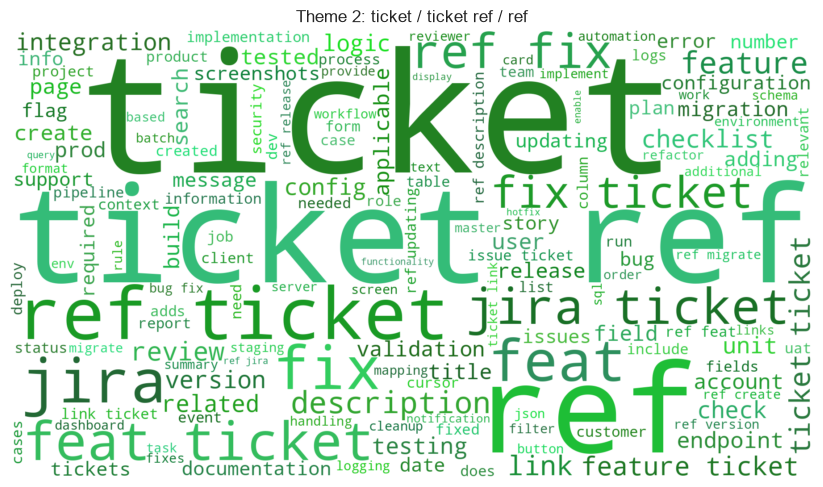

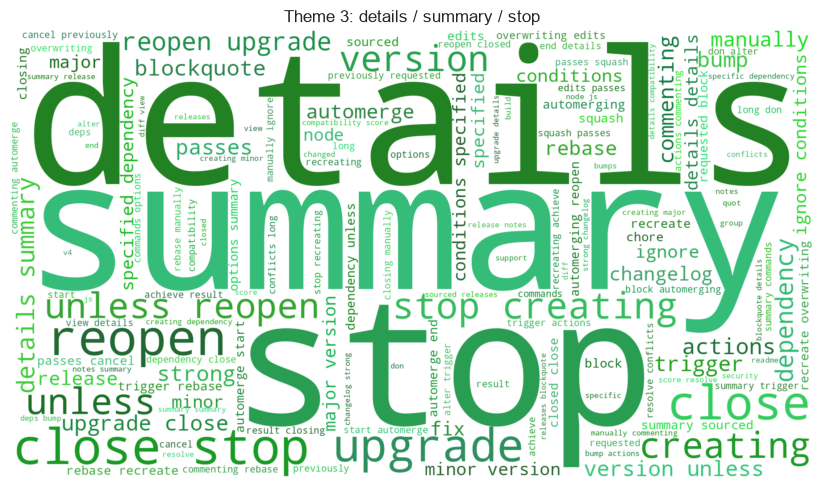

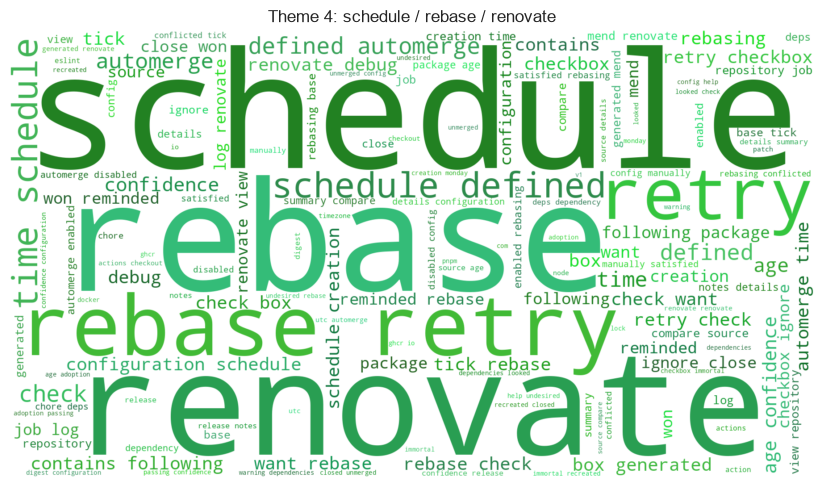

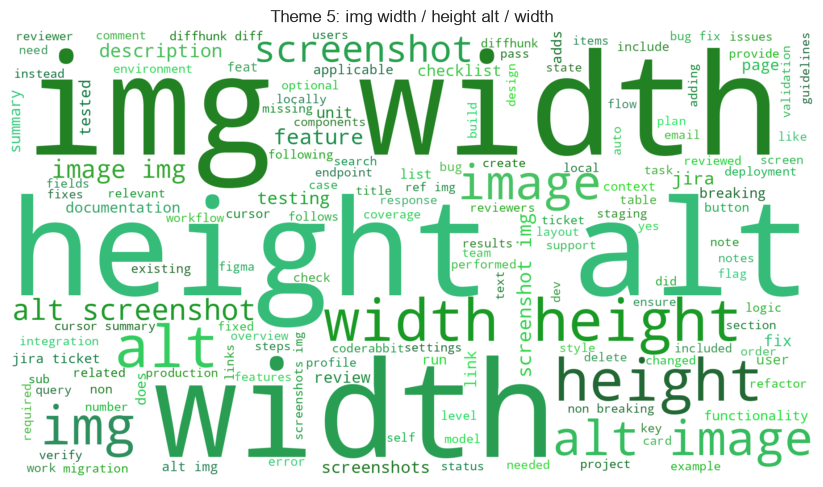

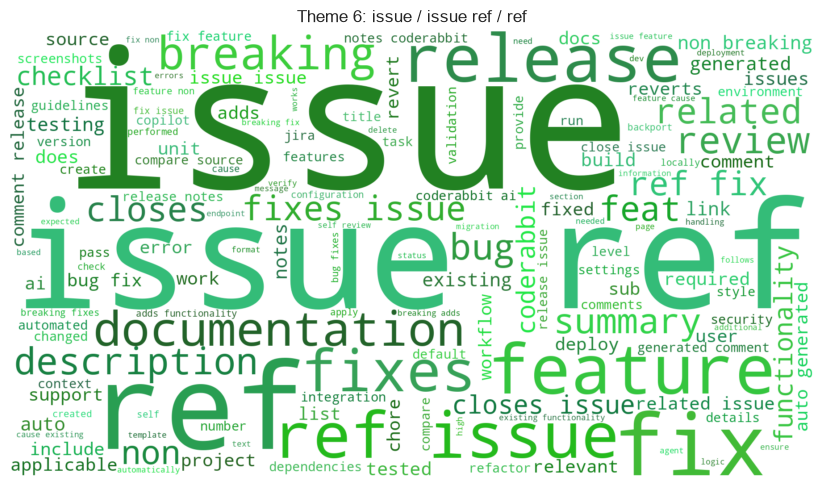

Saved theme summary to: ../nlp_outputs/discovered_theme_summary.csv
Saved document themes to: ../nlp_outputs/documents_with_discovered_themes.csv
Saved word clouds to: ../nlp_outputs/theme_wordclouds


In [37]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# -----------------------------
# Settings
# -----------------------------

TEXT_COL = "combined_text_nlp"
N_THEMES = 6          # Change to 5, 8, or 10 if needed
MAX_WORDS_CLOUD = 150

OUTPUT_DIR = Path("../nlp_outputs")
WC_DIR = OUTPUT_DIR / "theme_wordclouds"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WC_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Prepare text
# -----------------------------

texts = df[TEXT_COL].fillna("").astype(str).str.strip()
mask = texts.ne("")
texts_model = texts[mask]

min_df = 1 if len(texts_model) < 30 else 2 if len(texts_model) < 100 else 3

# -----------------------------
# Discover themes
# -----------------------------

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_df=0.90,
    min_df=min_df,
    max_features=8000,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(texts_model)
terms = vectorizer.get_feature_names_out()

n_themes = min(N_THEMES, X.shape[0], X.shape[1])

nmf = NMF(
    n_components=n_themes,
    random_state=42,
    init="nndsvda",
    max_iter=1000
)

doc_theme_matrix = nmf.fit_transform(X)
theme_term_matrix = nmf.components_

# -----------------------------
# Name themes automatically
# -----------------------------

def safe_filename(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z0-9_-]+", "_", text)
    return text.strip("_")[:80]

def green_color_func(word, font_size, position, orientation, random_state=None, **kwargs):
    random_state = random_state or np.random.RandomState(42)
    hue = random_state.randint(115, 150)
    saturation = random_state.randint(45, 80)
    lightness = random_state.randint(25, 52)
    return f"hsl({hue}, {saturation}%, {lightness}%)"

def top_terms(theme_idx, n=10):
    ids = theme_term_matrix[theme_idx].argsort()[::-1][:n]
    return [terms[i] for i in ids]

dominant_theme = doc_theme_matrix.argmax(axis=1)
theme_strength = doc_theme_matrix.max(axis=1)

theme_labels = {}
theme_summary = []

for i in range(n_themes):
    words = top_terms(i, 12)
    label = f"Theme {i + 1}: " + " / ".join(words[:3])
    theme_labels[i] = label

    theme_summary.append({
        "theme_id": i + 1,
        "theme_label": label,
        "top_terms": ", ".join(words),
        "n_documents": int((dominant_theme == i).sum())
    })

themes_df = pd.DataFrame(theme_summary).sort_values("n_documents", ascending=False)

display(themes_df)

# -----------------------------
# Add themes back to dataframe
# -----------------------------

df["theme_id"] = pd.NA
df["theme_label"] = pd.NA
df["theme_strength"] = pd.NA

df.loc[mask, "theme_id"] = dominant_theme + 1
df.loc[mask, "theme_label"] = [theme_labels[i] for i in dominant_theme]
df.loc[mask, "theme_strength"] = theme_strength

themes_df.to_csv(OUTPUT_DIR / "discovered_theme_summary.csv", index=False)
df.to_csv(OUTPUT_DIR / "documents_with_discovered_themes.csv", index=False)

# -----------------------------
# Generate word clouds by theme
# -----------------------------

for i in range(n_themes):
    top_ids = theme_term_matrix[i].argsort()[::-1][:MAX_WORDS_CLOUD]

    frequencies = {
        terms[j]: float(theme_term_matrix[i][j])
        for j in top_ids
        if theme_term_matrix[i][j] > 0
    }

    wc = WordCloud(
        width=1800,
        height=1000,
        background_color="white",
        max_words=MAX_WORDS_CLOUD,
        collocations=False,
        color_func=green_color_func,
        random_state=42,
    ).generate_from_frequencies(frequencies)

    label = theme_labels[i]

    plt.figure(figsize=(9, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(label, fontsize=12)
    plt.tight_layout()

    filename = f"wordcloud_theme_{i + 1:02d}_{safe_filename(label)}.png"

    plt.savefig(WC_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

print(f"Saved theme summary to: {OUTPUT_DIR / 'discovered_theme_summary.csv'}")
print(f"Saved document themes to: {OUTPUT_DIR / 'documents_with_discovered_themes.csv'}")
print(f"Saved word clouds to: {WC_DIR}")


## Top words, bigrams, and trigrams


In [47]:
from collections import Counter

row_tokens = [tokenize(text) for text in df["combined_text_nlp"].fillna("")]

unigram_counts = Counter(t for toks in row_tokens for t in toks)
bigram_counts = Counter()
trigram_counts = Counter()

for toks in row_tokens:
    bigram_counts.update(zip(toks, toks[1:]))
    trigram_counts.update(zip(toks, toks[1:], toks[2:]))

rows = []
for term, count in unigram_counts.most_common(100):
    rows.append({"ngram_type": "unigram", "term": term, "count": count})
for terms, count in bigram_counts.most_common(100):
    rows.append({"ngram_type": "bigram", "term": " ".join(terms), "count": count})
for terms, count in trigram_counts.most_common(100):
    rows.append({"ngram_type": "trigram", "term": " ".join(terms), "count": count})

top_phrases = pd.DataFrame(rows)
top_phrases.to_csv(OUTPUT_DIR / "top_words_and_phrases.csv", index=False)
top_phrases.head(10)


,ngram_type,term,count
0,unigram,summary,16202
1,unigram,details,15030
2,unigram,fix,11668
3,unigram,any,10073
4,unigram,strong,7673
5,unigram,can,7450
6,unigram,release,7075
7,unigram,version,7051
8,unigram,all,6563
9,unigram,dependency,6165


## TF-IDF keywords

TF-IDF helps find terms that characterize PRs without only rewarding the most frequent generic words.


In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer

MIN_DF = 3
MAX_FEATURES = 3000

docs = df["combined_text_nlp"].fillna("").astype(str)
docs = docs[docs.str.strip() != ""]

vectorizer = TfidfVectorizer(
    stop_words=list(STOPWORDS),
    ngram_range=(1, 3),
    min_df=MIN_DF,
    max_features=MAX_FEATURES,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9+#.]{2,}\b",
)
X = vectorizer.fit_transform(docs)
terms = vectorizer.get_feature_names_out()
mean_scores = np.asarray(X.mean(axis=0)).ravel()
doc_counts = np.asarray((X > 0).sum(axis=0)).ravel()

tfidf_terms = pd.DataFrame({"term": terms, "mean_tfidf": mean_scores, "document_count": doc_counts})
tfidf_terms = tfidf_terms.sort_values(["document_count"], ascending=False)
tfidf_terms.to_csv(OUTPUT_DIR / "tfidf_top_terms_overall.csv", index=False)
tfidf_terms.head(15)


,term,mean_tfidf,document_count
2578,summary,0.022287,4436
1141,fix,0.028290,3949
859,details,0.020963,3666
110,all,0.014001,3650
148,any,0.016661,3620
406,can,0.014816,3604
1674,more,0.013511,3027
1732,not,0.014852,2960
2128,release,0.017299,2789
1905,please,0.014191,2664


## BERTopic categories

BERTopic uses transformer embeddings plus topic clustering to discover semantic categories in the cleaned PR text. This section reduces the model to 10 categories and saves both a category report and row-level topic assignments.

In [51]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

N_BERTOPIC_CATEGORIES = 10
MIN_TOPIC_SIZE = 10

bertopic_docs = df["combined_text_nlp"].fillna("").astype(str).str.strip()
bertopic_docs = bertopic_docs[bertopic_docs != ""]

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
vectorizer_model = CountVectorizer(
    stop_words=list(STOPWORDS),
    ngram_range=(1, 3),
    min_df=MIN_DF,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9+#.]{2,}\b",
)
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
hdbscan_model = HDBSCAN(
    min_cluster_size=MIN_TOPIC_SIZE,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True,
)

bertopic_model = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    nr_topics=N_BERTOPIC_CATEGORIES,
    calculate_probabilities=True,
    verbose=True,
)

topic_ids, topic_probabilities = bertopic_model.fit_transform(bertopic_docs.tolist())

topic_info = bertopic_model.get_topic_info()
category_report = topic_info[topic_info["Topic"] != -1].head(N_BERTOPIC_CATEGORIES).copy()
category_report["category_rank"] = range(1, len(category_report) + 1)
category_report["top_terms"] = category_report["Topic"].apply(
    lambda topic_id: ", ".join(term for term, _ in bertopic_model.get_topic(topic_id)[:10])
)
report_columns = [
    "category_rank",
    "Topic",
    "Name",
    "Count",
    "top_terms",
    "Representation",
    "Representative_Docs",
]
category_report = category_report[[col for col in report_columns if col in category_report.columns]]
category_report.to_csv(OUTPUT_DIR / "bertopic_10_category_report.csv", index=False)

bertopic_assignments = df.loc[bertopic_docs.index].copy()
bertopic_assignments["bertopic_topic_id"] = topic_ids
bertopic_assignments["bertopic_topic_probability"] = [
    float(np.nanmax(probabilities)) if topic_id >= 0 and probabilities is not None else np.nan
    for topic_id, probabilities in zip(topic_ids, topic_probabilities)
]
bertopic_assignments = bertopic_assignments.merge(
    category_report[["Topic", "category_rank", "Name", "top_terms"]],
    left_on="bertopic_topic_id",
    right_on="Topic",
    how="left",
).drop(columns=["Topic"])
bertopic_assignments.to_csv(OUTPUT_DIR / "documents_with_bertopic_categories.csv", index=False)

category_report

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8668.53it/s]
2026-08-19 16:01:53,525 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 519/519 [00:26<00:00, 19.28it/s] 
2026-08-19 16:02:20,485 - BERTopic - Embedding - Completed ✓
2026-08-19 16:02:20,485 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-08-19 16:02:28,278 - BERTopic - Dimensionality - Completed ✓
2026-08-19 16:02:28,278 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-08-19 16:02:47,599 - BERTopic - Cluster - Completed ✓
2026-08-19 16:02:47,599 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-08-19 16:02:49,308 - BERTopic - Representation - Completed ✓
2026-08-19 16:02:49,308 - BERTopic - Topic reduction - Reducing number of topics
2026-08-19 16:02:49,316 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-08-19 16:02:50,935 - BERTopic - Representation -

,category_rank,Topic,Name,Count,top_terms,Representation,Representative_Docs
1,1,0,0_summary_details_any_strong,7945,"summary, details, any, strong, fix, can, release, version, details summary, dependency","[summary, details, any, strong, fix, can, release, version, details summary, dependency]",[bump autoprefixer start rebasing rebasing might not happen immediately don worry takes some tim...
2,2,1,1_translations_translation_copilot_language,291,"translations, translation, copilot, language, date, review, copilot review, review rule, localiz...","[translations, translation, copilot, language, date, review, copilot review, review rule, locali...",[account want review japanese playwright pnpm playwright pnpm playwright safari mac ios account ...
3,3,2,2_filter_search_sort_filters,152,"filter, search, sort, filters, fix, query, filtering, when, opensearch, not","[filter, search, sort, filters, fix, query, filtering, when, opensearch, not]","[implaments search disliked songs, support filter rechunk, fixing filters state issues fixed fil..."
4,4,3,3_pytest_python_cpython_compatibility,56,"pytest, python, cpython, compatibility, windows, asyncio, reference, pytest dev, dependency, numpy","[pytest, python, cpython, compatibility, windows, asyncio, reference, pytest dev, dependency, nu...",[pip bump pytest backend humeai chat reconstructor bumps pytest details summary release notes su...
5,5,4,4_roll_pdf_unsafe_usage,32,"roll, pdf, unsafe, usage, face, todo, print, blueprint, computed, rid","[roll, pdf, unsafe, usage, face, todo, print, blueprint, computed, rid]",[dedicated print button auto opens print dialog generated pdf motivation provide separate action...
6,6,5,5_helm_turbo_automated_,26,"helm, turbo, automated, , , , , , ,","[helm, turbo, automated, , , , , , , ]","[helm updation automated turbo turtle helm, helm updation automated turbo turtle helm, helm upda..."
7,7,6,6_digest_build system_automatically created_push,21,"digest, build system, automatically created, push, record, tags, system, automatically, log, cre...","[digest, build system, automatically created, push, record, tags, system, automatically, log, cr...","[log push dhi csi provisioner automatically created dhi build system record digest digest tags, ..."
8,8,7,7_category_categories_nba_red,15,"category, categories, nba, red, failing, save, product, after review, product category, field me...","[category, categories, nba, red, failing, save, product, after review, product category, field m...","[category category rapid regression cases, feature category subcategory, categories recyclerview]"
9,9,8,8_group_org_group name_groups,12,"group, org, group name, groups, name, send, group context, field send, dbd, fix group","[group, org, group name, groups, name, send, group context, field send, dbd, fix group]","[group members name, imanage group field, chore integrations adding org group name fullstory con..."
